# Hari 1, Sesi 2: Bentuk Fungsional Model Regresi

**Durasi:** 75 menit

Hubungan ekonomi jarang berbentuk garis lurus. Sesi ini membahas lima bentuk
fungsional yang muncul terus di perkuliahan, lengkap dengan cara menafsirkan
koefisiennya.

| Bentuk | Persamaan | Makna koefisien |
|---|---|---|
| Linear | $Y = \beta_0 + \beta_1 X$ | tambahan 1 unit X menaikkan Y sebesar $\beta_1$ unit |
| Log-lin | $\ln Y = \beta_0 + \beta_1 X$ | tambahan 1 unit X menaikkan Y sekitar $100\beta_1$ persen |
| Lin-log | $Y = \beta_0 + \beta_1 \ln X$ | kenaikan X 1 persen menaikkan Y sebesar $\beta_1/100$ unit |
| Log-log | $\ln Y = \beta_0 + \beta_1 \ln X$ | elastisitas: kenaikan X 1 persen menaikkan Y $\beta_1$ persen |
| Reciprocal | $Y = \beta_0 + \beta_1 \frac{1}{X}$ | efek mengecil saat X membesar, ada batas asimtot $\beta_0$ |
| Polinomial | $Y = \beta_0 + \beta_1 X + \beta_2 X^2$ | bisa naik lalu turun, ada titik puncak |

## Persiapan: pastikan data tersedia

Notebook ini membaca CSV dari folder `data/`. Kalau belum ada (misalnya di
Colab), unggah `data_tutorial.zip` lewat panel Files, lalu jalankan
sel di bawah sekali.



**Posisi dalam alur workshop.** Melanjutkan Sesi 1 yang berakhir dengan
model linear yang gagal. Setelah bentuk model tepat, Sesi 3 memeriksa
kelayakan asumsinya.



## Cara mengikuti notebook ini

Jalankan sel berurutan dengan `Shift + Enter`. Setiap notebook dapat
dimulai sendiri setelah paket data diunggah. Sel persiapan cukup dijalankan
apa adanya; fokus latihan dimulai saat tabel data muncul.

Baca penjelasan sebelum menjalankan kode, lalu sebutkan arti hasilnya.
Ubah satu hal setiap mencoba: nama kolom pada X, pilihan model, atau nilai prediksi.
Baris `#` adalah catatan. `=` menyimpan hasil dan `==` membandingkan nilai.
Contoh `tabel["kolom"]` berarti memilih satu kolom dari tabel.

Jika muncul error merah, berhenti di sel itu dan baca baris terakhirnya.
Jika ada warning, baca pesannya dan periksa hasil estimasi sebelum lanjut.
Panduan simbol dan contoh tambahan ada di `panduan/01_panduan_pemula.md`.



### Pola pemodelan yang dipakai

`X` adalah tabel fitur dan `y` adalah kolom target. Model utama memakai
scikit-learn: buat model, jalankan `fit(X, y)`, lalu gunakan `predict(X_baru)`.
Koefisien ada pada `coef_` dan intersep pada `intercept_`. Tabel `koefisien_...`
hanya memberi nama kolom agar angka mudah dibaca. `score(X, y)` pada regresi
linear adalah R² pada data yang diberikan; hasil pada data latih belum mengukur
kemampuan memprediksi data baru.

Nama `uji_...` menandai pelengkap statistik untuk p-value, standard error, atau
uji asumsi. Perhitungannya memakai X dan y yang sama. Bagian model khusus diberi
catatan tersendiri ketika scikit-learn belum menyediakan estimatornya.



In [1]:
import os
import zipfile
from pathlib import Path

# Di komputer sendiri, temukan folder data dari lokasi notebook ini.
# Di Colab, folder kerja tetap memakai lokasi unggahan Anda.
if not Path("data").is_dir() and Path("../../data").is_dir():
    os.chdir("../..")

# Jalankan apa adanya. Paket dibuka jika alat bantu belum tersedia.
# Jika data sudah siap, menjalankan ulang sel ini tidak menimpa CSV.
if (
    Path("data_tutorial.zip").exists()
    and not Path("alat_bantu/metode_lanjutan.py").exists()
):
    with zipfile.ZipFile("data_tutorial.zip") as paket:
        paket.extractall(".")

if not Path("data/uts_2.csv").exists():
    raise FileNotFoundError(
        "Unggah data_tutorial.zip lewat panel Files di kiri Colab, "
        "lalu jalankan sel ini lagi."
    )

print("Data siap. Lanjutkan ke sel berikutnya.")



Data siap. Lanjutkan ke sel berikutnya.


## Kasus 1: Fungsi produksi Cobb-Douglas (log-log)

Data 30 observasi tenaga kerja (L), modal (K), dan produksi (Q) dari
`regresi_log.csv`. Model yang diuji: $Q = A L^{\beta_1} K^{\beta_2}$.
Setelah di-log, bentuknya linear dan koefisiennya elastisitas.



In [2]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette=["#2F5D50", "#C15937", "#D9A441", "#5B8A8F"])
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "font.size": 11})

produksi = pd.read_csv("data/regresi_log.csv")
produksi = produksi.rename(
    columns={
        "Observasi ke-": "obs",
        "Tenaga Kerja (L)": "L",
        "Modal (K)": "K",
        "Produksi (Q)": "Q",
    }
)
produksi["lnQ"] = np.log(produksi["Q"])
produksi["lnL"] = np.log(produksi["L"])
produksi["lnK"] = np.log(produksi["K"])
produksi.head()



,obs,L,K,Q,lnQ,lnL,lnK
0,1,51,102,68.91,4.232801,3.931826,4.624973
1,2,53,105,72.15,4.278747,3.970292,4.653960
2,3,54,109,75.01,4.317621,3.988984,4.691348
3,4,56,112,78.23,4.359653,4.025352,4.718499
4,5,59,115,82.55,4.413404,4.077537,4.744932


In [3]:
sampel_model_cd = produksi[["lnQ", "lnL", "lnK"]].dropna()
X_model_cd = sampel_model_cd[["lnL", "lnK"]]
y_model_cd = sampel_model_cd["lnQ"]

model_cd = LinearRegression()
model_cd.fit(X_model_cd, y_model_cd)

koefisien_model_cd = pd.Series(model_cd.coef_, index=X_model_cd.columns)
koefisien_model_cd.loc["Intercept"] = model_cd.intercept_

# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_cd = sm.OLS(
    y_model_cd,
    sm.add_constant(X_model_cd, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()
print(uji_model_cd.summary())



                            OLS Regression Results                            
Dep. Variable:                    lnQ   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 9.819e+04
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           7.35e-53
Time:                        15:25:39   Log-Likelihood:                 119.60
No. Observations:                  30   AIC:                            -233.2
Df Residuals:                      27   BIC:                            -229.0
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.9921      0.110    -18.034      0.0

Baca koefisien `lnL` dan `lnK` sebagai elastisitas. Kalau `lnL` = 0,6,
tambahan tenaga kerja 1 persen menaikkan produksi sekitar 0,6 persen.

Jumlah kedua elastisitas menentukan skala pengembalian (returns to scale):

- $\beta_1 + \beta_2 = 1$: skala tetap (constant returns to scale)
- $> 1$: skala meningkat
- $< 1$: skala menurun



In [4]:
b_L = koefisien_model_cd["lnL"]
b_K = koefisien_model_cd["lnK"]
print(f"Elastisitas tenaga kerja : {b_L:.4f}")
print(f"Elastisitas modal        : {b_K:.4f}")
print(f"Jumlah (skala)           : {b_L + b_K:.4f}")

# Uji gabungan: apakah skalanya tepat 1?
print(uji_model_cd.f_test("lnL + lnK = 1"))



Elastisitas tenaga kerja : 0.8635
Elastisitas modal        : 0.6093
Jumlah (skala)           : 1.4728
<F test: F=1834.0797723757246, p=2.3268827408684862e-26, df_denom=27, df_num=1>


### Catatan untuk mengajar

Pada model log-lin (ln Y dijelaskan X), aproksimasi "100 x beta persen"
cukup akurat untuk beta kecil. Untuk
beta di atas 0,15 lebih baik pakai rumus eksak $100(e^{\beta} - 1)$.
Contoh: beta = 0,25. Aproksimasi bilang 25 persen, eksak 28,4 persen.
Sebutkan ini sekali saja, jangan sampai mahasiswa tersesat di detail.



In [5]:
beta = 0.25
print(f"Aproksimasi 100*beta     : {100 * beta:.2f} persen")
print(f"Eksak 100*(exp(beta)-1)  : {100 * (np.exp(beta) - 1):.2f} persen")



Aproksimasi 100*beta     : 25.00 persen
Eksak 100*(exp(beta)-1)  : 28.40 persen


### Coba sendiri (5 menit)

Menurut model log-log di atas, kalau modal naik 10 persen, berapa
persen produksi diperkirakan naik? (Kalikan elastisitasnya.)

Tulis di sel di bawah, baru buka jawabannya.



In [6]:
# Tulis jawaban singkat Anda di sini



<details><summary>Lihat jawaban</summary>

Elastisitas modal 0,6093, jadi kenaikan 10 persen modal berhubungan
dengan kenaikan produksi sekitar 6,1 persen, ceteris paribus.

</details>



## Kasus 2: Regresi reciprocal

Data pengalaman kerja (X) dan waktu produksi (Y) dari
`regresi_reciprocal.csv`. Hubungan yang diduga: makin berpengalaman,
waktu produksi makin pendek, tapi perbaikannya mengecil dan mendekati
batas tertentu.

$$Y = \beta_0 + \beta_1 \left(\frac{1}{X}\right)$$

Kalau X membesar, $1/X$ mendekati nol, jadi Y mendekati $\beta_0$. Nilai
$\beta_0$ adalah batas waktu produksi teoretis yang tidak bisa dilewati.



In [7]:
recip = pd.read_csv("data/regresi_reciprocal.csv")
recip = recip.rename(
    columns={"Pengalaman (X)": "pengalaman", "Waktu Produksi (Y)": "waktu"}
)
recip["satu_per_x"] = 1 / recip["pengalaman"]
sampel_model_r = recip[["waktu", "satu_per_x"]].dropna()
X_model_r = sampel_model_r[["satu_per_x"]]
y_model_r = sampel_model_r["waktu"]

model_r = LinearRegression()
model_r.fit(X_model_r, y_model_r)

koefisien_model_r = pd.Series(model_r.coef_, index=X_model_r.columns)
koefisien_model_r.loc["Intercept"] = model_r.intercept_

# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_r = sm.OLS(
    y_model_r,
    sm.add_constant(X_model_r, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()
print(uji_model_r.summary())



                            OLS Regression Results                            
Dep. Variable:                  waktu   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 2.287e+05
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           2.54e-56
Time:                        15:25:39   Log-Likelihood:                 25.041
No. Observations:                  30   AIC:                            -46.08
Df Residuals:                      28   BIC:                            -43.28
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      4.9835      0.024    205.542      0.0

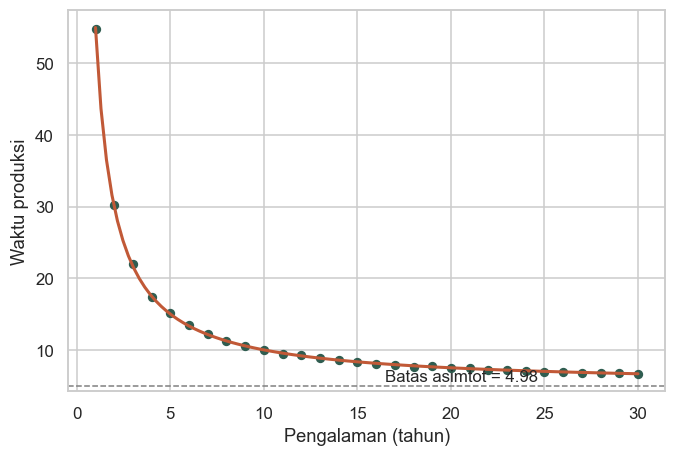

In [8]:
b0r = koefisien_model_r["Intercept"]
b1r = koefisien_model_r["satu_per_x"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(recip["pengalaman"], recip["waktu"], color="#2F5D50", s=26)
xs = np.linspace(recip["pengalaman"].min(), recip["pengalaman"].max(), 100)
ax.plot(xs, b0r + b1r / xs, color="#C15937", lw=2)
ax.axhline(b0r, color="gray", ls="--", lw=1)
ax.text(xs.max() * 0.55, b0r + 0.6, f"Batas asimtot = {b0r:.2f}")
ax.set_xlabel("Pengalaman (tahun)")
ax.set_ylabel("Waktu produksi")
plt.show()



## Kasus 3: Regresi polinomial

Kasus yang sama seperti sesi 1 (biaya iklan dan penjualan), tapi sekarang
kita curiga ada titik jenuh: iklan menambah penjualan, tapi lama-lama
tambahannya berkurang, lalu berbalik menurun.

Model: $\text{penjualan} = \beta_0 + \beta_1 X + \beta_2 X^2$.
Titik puncak berada di $X^* = -\beta_1 / (2\beta_2)$.



In [9]:
polinom = pd.read_csv("data/regresi_polinom.csv")
polinom = polinom.rename(
    columns={"Biaya Iklan (X)": "iklan", "Penjualan (Y)": "penjualan"}
)
polinom["iklan2"] = polinom["iklan"] ** 2

# Regresi yang sama dengan `model_salah` di Sesi 1; di sini dipakai
# sebagai pembanding model polinomial
sampel_model_lin = polinom[["penjualan", "iklan"]].dropna()
X_model_lin = sampel_model_lin[["iklan"]]
y_model_lin = sampel_model_lin["penjualan"]

model_lin = LinearRegression()
model_lin.fit(X_model_lin, y_model_lin)

koefisien_model_lin = pd.Series(model_lin.coef_, index=X_model_lin.columns)
koefisien_model_lin.loc["Intercept"] = model_lin.intercept_

# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_lin = sm.OLS(
    y_model_lin,
    sm.add_constant(X_model_lin, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()
sampel_model_poli = polinom[["penjualan", "iklan", "iklan2"]].dropna()
X_model_poli = sampel_model_poli[["iklan", "iklan2"]]
y_model_poli = sampel_model_poli["penjualan"]

model_poli = LinearRegression()
model_poli.fit(X_model_poli, y_model_poli)

koefisien_model_poli = pd.Series(model_poli.coef_, index=X_model_poli.columns)
koefisien_model_poli.loc["Intercept"] = model_poli.intercept_

# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_poli = sm.OLS(
    y_model_poli,
    sm.add_constant(X_model_poli, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()

print(f"Adj R2 linear    : {uji_model_lin.rsquared_adj:.4f}")
print(f"Adj R2 polinomial: {uji_model_poli.rsquared_adj:.4f}")
print(
    f"Koefisien X2     : {koefisien_model_poli['iklan2']:.4f} "
    f"(p = {uji_model_poli.pvalues['iklan2']:.4f})"
)



Adj R2 linear    : -0.0289
Adj R2 polinomial: 0.9997
Koefisien X2     : -0.1069 (p = 0.0000)


Titik puncak pada X = 26.28


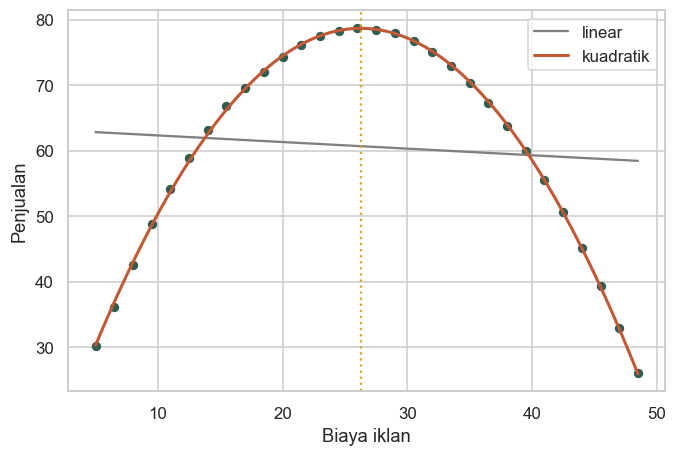

In [10]:
b1p = koefisien_model_poli["iklan"]
b2p = koefisien_model_poli["iklan2"]
# Pada data ini koefisien kuadrat negatif, sehingga titik balik adalah puncak.
puncak = -b1p / (2 * b2p)
print(f"Titik puncak pada X = {puncak:.2f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(polinom["iklan"], polinom["penjualan"], color="#2F5D50", s=26)
xs = np.linspace(polinom["iklan"].min(), polinom["iklan"].max(), 100)
ax.plot(
    xs,
    koefisien_model_lin["Intercept"] + koefisien_model_lin["iklan"] * xs,
    color="gray",
    lw=1.5,
    label="linear",
)
ax.plot(
    xs,
    koefisien_model_poli["Intercept"] + b1p * xs + b2p * xs**2,
    color="#C15937",
    lw=2,
    label="kuadratik",
)
ax.axvline(puncak, color="#D9A441", ls=":", lw=1.5)
ax.legend()
ax.set_xlabel("Biaya iklan")
ax.set_ylabel("Penjualan")
plt.show()



## Contoh soal dari halaman kuliah: usia dan kinerja penjualan

Hipotesis di materi Pertemuan 3: kinerja naik seiring usia, memuncak di
usia tertentu, lalu menurun. Model kuadratik adalah jawaban standarnya.



In [11]:
usia = pd.read_csv("data/usia_unit.csv")
usia = usia.rename(columns={"Usia": "usia", "Unit_Terjual": "unit"})
usia["usia2"] = usia["usia"] ** 2

sampel_model_usia = usia[["unit", "usia", "usia2"]].dropna()
X_model_usia = sampel_model_usia[["usia", "usia2"]]
y_model_usia = sampel_model_usia["unit"]

model_usia = LinearRegression()
model_usia.fit(X_model_usia, y_model_usia)

koefisien_model_usia = pd.Series(model_usia.coef_, index=X_model_usia.columns)
koefisien_model_usia.loc["Intercept"] = model_usia.intercept_

# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_usia = sm.OLS(
    y_model_usia,
    sm.add_constant(X_model_usia, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()
print(uji_model_usia.summary())



                            OLS Regression Results                            
Dep. Variable:                   unit   R-squared:                       0.999
Model:                            OLS   Adj. R-squared:                  0.999
Method:                 Least Squares   F-statistic:                 1.505e+04
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           7.17e-42
Time:                        15:25:40   Log-Likelihood:                -18.198
No. Observations:                  30   AIC:                             42.40
Df Residuals:                      27   BIC:                             46.60
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -88.9325      1.347    -66.013      0.0

In [12]:
ba = koefisien_model_usia["usia"]
bb = koefisien_model_usia["usia2"]
print(f"Usia puncak = {(-ba / (2 * bb)):.2f} tahun")



Usia puncak = 39.46 tahun


Usia puncaknya sekitar 40 tahun, cocok dengan hipotesis di soal. Perhatikan
`usia2` bernilai negatif: itulah yang membuat kurvanya melengkung ke bawah.



### Coba sendiri (5 menit)

Data `data/jam_skor.csv` punya efek jenuh. Jalankan model reciprocal
`Skor_Ujian ~ 1/Jam_Belajar`, lalu sebutkan batas skor maksimalnya.

Tulis di sel di bawah, baru buka jawabannya.



In [13]:
# Tulis kode Anda di sini



<details><summary>Lihat jawaban</summary>

Intersep (asimtot) = 99,73. Skor mendekati 100 tapi tidak pernah
melewatinya; itulah bentuk khas reciprocal.

</details>



## Cara memilih bentuk fungsional

Urutannya: teori dulu, data kemudian.

1. Tanya dulu hubungan ekonominya seperti apa. Elastisitas konstan? Pakai
   log-log. Ada titik jenuh? Pakai kuadratik atau reciprocal.
2. Baru bandingkan kecocokan. R kuadrat hanya boleh dibandingkan kalau
   variabel Y-nya sama. Log-lin dan linear tidak bisa dibanding R kuadrat
   langsung, karena Y-nya beda skala.
3. Periksa pola residual. Kalau residual membentuk lengkungan, model linear
   kemungkinan kurang tepat.
4. Ingat batas praktis: log tidak bisa dipakai kalau ada nilai nol atau
   negatif.



## Latihan

1. Regresikan `waktu` pada `1/pengalaman` dan hitung prediksi untuk
   pengalaman 6 bulan. Apa arti batas asimtot di kasus ini?
2. Pada model usia di atas, bandingkan R kuadrat terkoreksi model
   kuadratik dengan model linear (`unit ~ usia`). Apakah tambahan `usia2`
   sepadan?
3. Data `regresi_log.csv`: uji apakah model skala tetap ditolak. Pakai
   hasil `f_test` yang sudah dijalankan.



### Selanjutnya

Selanjutnya: Sesi 3 memeriksa apakah model sudah memenuhi asumsi klasik.
